# Tip-of-the-Tongue Book Finder

Hybrid search (BM25 + dense embeddings + cross-encoder reranker) over the CMU Book Summary Dataset.

**Notebook outline**
1. Load and inspect the data
2. Gold test set (60 queries)
3. BM25 baseline
4. Dense search
5. Fusion and reranker
6. Evaluation table

The API and frontend live in `app/`. This notebook is for exploration and experiments only.

## 1. Load and inspect the data

This notebook reads `data/raw/booksummaries_genres_filled.csv`. It keeps the original dataset genres and includes predicted genres for books that were missing them.

The CSV has a header row, so pandas reads it directly.

In [43]:
import json
import pandas as pd
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent

PATH = ROOT / "data/raw/booksummaries_genres_filled.csv"
print("file found:", PATH.exists())

COLS = ["wiki_id", "freebase_id", "title", "author", "pub_date", "genres", "summary"]
df = pd.read_csv(PATH, usecols=COLS, dtype={"wiki_id": str})
df.shape

file found: True


(16559, 7)

### Keep genre labels ready for filtering

The filled CSV already contains readable genre names. This step also handles JSON-formatted genre labels if they are encountered.

In [44]:
def clean_genres(value):
    if not isinstance(value, str) or not value.strip():
        return ""
    try:
        parsed = json.loads(value)
        if isinstance(parsed, dict):
            return " | ".join(str(name) for name in parsed.values())
    except json.JSONDecodeError:
        pass
    return value

df["genres"] = df["genres"].apply(clean_genres)
df["summary_words"] = df["summary"].fillna("").astype(str).str.split().str.len()
df.head(3)

,wiki_id,freebase_id,title,author,pub_date,genres,summary,summary_words
0,620,/m/0hhy,Animal Farm,George Orwell,1945-08-17,Roman à clef | Satire | Children's literature | Speculative fiction | Fiction,"Old Major, the old boar on the Manor Farm, calls the animals on the farm for a meeting, where he compares the human...",957
1,843,/m/0k36,A Clockwork Orange,Anthony Burgess,1962,Science Fiction | Novella | Speculative fiction | Utopian and dystopian fiction | Satire | Fiction,"Alex, a teenager living in near-future England, leads his gang on nightly orgies of opportunistic, random ""ultra-vi...",998
2,986,/m/0ldx,The Plague,Albert Camus,1947,Existentialism | Fiction | Absurdist fiction | Novel,"The text of The Plague is divided into five parts. In the town of Oran, thousands of rats, initially unnoticed by t...",1119


In [45]:
import pandas as pd

source_path = ROOT / "data" / "raw" / "booksummaries" / "booksummaries.txt"
csv_path = ROOT / "data" / "raw" / "booksummaries.csv"

columns = [
    "wiki_id",
    "freebase_id",
    "title",
    "author",
    "publication_date",
    "genres",
    "summary",
]

books = pd.read_csv(
    source_path,
    sep="\t",
    header=None,
    names=columns,
    dtype=str,
    keep_default_na=False,
)
books.to_csv(csv_path, index=False, encoding="utf-8")

print(f"Saved {len(books):,} books to {csv_path}")
print(csv_path.read_text(encoding="utf-8")[:200])

Saved 16,559 books to /Users/shreyas/Desktop/THWS/2nd sem/NLP/Portfolio 2/data/raw/booksummaries.csv
wiki_id,freebase_id,title,author,publication_date,genres,summary
620,/m/0hhy,Animal Farm,George Orwell,1945-08-17,"{""/m/016lj8"": ""Roman \u00e0 clef"", ""/m/06nbt"": ""Satire"", ""/m/0dwly"": ""Chil


### Inspect: missing values, lengths, duplicates

Checking three things before building anything:
- which columns have missing values
- how long the summaries are (this decides how we embed them)
- how many titles appear more than once (these will be near-duplicates for the reranker)

In [46]:
print("missing values per column:")
print(df.isna().sum())
print("\nsummary length in words:")
print(df["summary_words"].describe())
print("\nduplicate titles:", df["title"].duplicated().sum())
df[["title", "author", "genres"]].sample(5, random_state=1)

missing values per column:
wiki_id             0
freebase_id         0
title               0
author           2382
pub_date         5610
genres              0
summary             0
summary_words       0
dtype: int64

summary length in words:
count    16559.000000
mean       429.202126
std        500.339692
min          1.000000
25%        120.000000
50%        263.000000
75%        569.000000
max      10334.000000
Name: summary_words, dtype: float64

duplicate titles: 282


,title,author,genres
10091,Echo Park,Michael Connelly,Crime Fiction | Mystery | Fiction | Suspense
10761,Saints of Big Harbour,NaN,Children's literature
5039,Engine Summer,John Crowley,Science Fiction | Speculative fiction
4382,The Staircase,Ann Rinaldi,Children's literature | Historical fiction | Speculative fiction | Fiction
1610,Hornet Flight,Ken Follett,Thriller | Young adult literature | Fiction


### What does one record look like?

Each row is one book. Below is the first book (*Animal Farm*) shown as a column-by-column list, with the summary cut to 300 characters so it fits on screen.

In [47]:
pd.set_option("display.max_colwidth", 120)

row = df.iloc[0].copy()
row["summary"] = row["summary"][:300] + " ..."
row

wiki_id                                                                                                                              620
freebase_id                                                                                                                      /m/0hhy
title                                                                                                                        Animal Farm
author                                                                                                                     George Orwell
pub_date                                                                                                                      1945-08-17
genres                                                     Roman à clef | Satire | Children's literature | Speculative fiction | Fiction
summary           Old Major, the old boar on the Manor Farm, calls the animals on the farm for a meeting, where he compares the human...
summary_words                            

### Column overview

For every column: its data type, how many values are missing, and how many distinct values it has.

Note that `genres` shows 0 missing because an empty genre list was stored as an empty string, not as NaN. We count those separately in the genre section below.

In [48]:
pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(1),
    "distinct_values": df.nunique(),
})

,dtype,missing,missing_%,distinct_values
wiki_id,str,0,0.0,16559
freebase_id,str,0,0.0,16559
title,str,0,0.0,16277
author,str,2382,14.4,4714
pub_date,str,5610,33.9,2639
genres,str,0,0.0,2154
summary,str,0,0.0,16532
summary_words,int64,0,0.0,1885


### Summary length

Summary length matters for two reasons:
- **Dense search:** embedding models read only the first few hundred tokens. One word is roughly 1.3 tokens, so anything much beyond 200 words is partly invisible to the model.
- **BM25:** long documents contain more words, so they match more queries by chance. BM25 corrects for this, but it is worth knowing how extreme the lengths are.

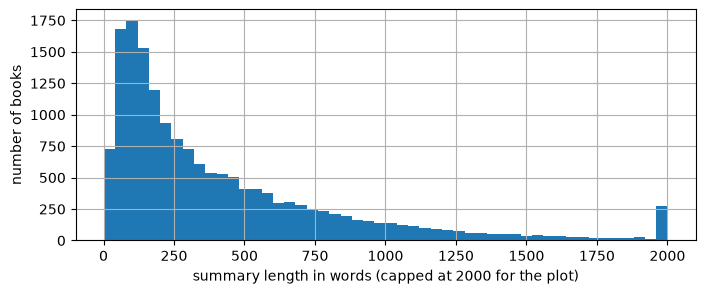

under   20 words:    203 (1%)   over   20 words:  16323 (99%)
under  200 words:   6859 (41%)   over  200 words:   9670 (58%)
under 1000 words:  14956 (90%)   over 1000 words:   1602 (10%)


In [49]:
import matplotlib.pyplot as plt

ax = df["summary_words"].clip(upper=2000).hist(bins=50, figsize=(8, 3))
ax.set_xlabel("summary length in words (capped at 2000 for the plot)")
ax.set_ylabel("number of books")
plt.show()

n = len(df)
for limit in (20, 200, 1000):
    shorter = (df["summary_words"] < limit).sum()
    longer = (df["summary_words"] > limit).sum()
    print(f"under {limit:>4} words: {shorter:>6} ({shorter/n:.0%})   over {limit:>4} words: {longer:>6} ({longer/n:.0%})")

### The shortest summaries

Some summaries are only a few words long. These books have almost no text to search, so they will be hard for every method. It is worth knowing which ones they are before we write test queries.

In [50]:
df.nsmallest(8, "summary_words")[["title", "author", "summary_words", "summary"]]

,title,author,summary_words,summary
5693,The Deathlord of Ixia,John Grant,1,==Receptio
5879,The Caverns of Kalte,Joe Dever,1,==Receptio
5972,The Eyes of Darkness,Dean Koontz,1,==Character
11215,Chucaro: Wild Pony of the Pampa,Francis Kalnay,1,==Reference
15789,Lurulu,Jack Vance,1,==Reference
16531,Guardians of Ga'Hoole Book 4: The Siege,Helen Dunmore,1,==Receptio
3879,Slavers,Chris Pramas,2,==Publication histor
5271,Golem in the Gears,Piers Anthony,2,pl:Zakochany golem


### Genres

Each book can have several genres. We split them into one row per genre to count them. Books with no genre label are counted separately.

books with no genre: 0
distinct genres: 227


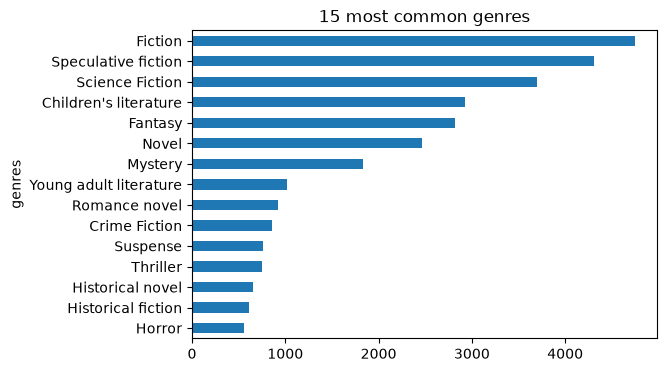

In [51]:
genre_counts = (
    df["genres"].str.split(" | ", regex=False).explode()
    .loc[lambda s: s != ""]
    .value_counts()
)
print("books with no genre:", (df["genres"] == "").sum())
print("distinct genres:", len(genre_counts))

genre_counts.head(15).sort_values().plot.barh(figsize=(6, 4), title="15 most common genres")
plt.show()

### Publication years and authors

Publication dates come in mixed formats (`1945-08-17`, `1962`), so we keep only the first four characters as the year. A large share of dates is missing.

We also check which authors appear most often. Prolific authors and book series are where near-duplicate summaries come from.

count    10949.0
mean      1976.0
std         50.0
min        398.0
25%       1966.0
50%       1991.0
75%       2003.0
max       2013.0
Name: year, dtype: float64


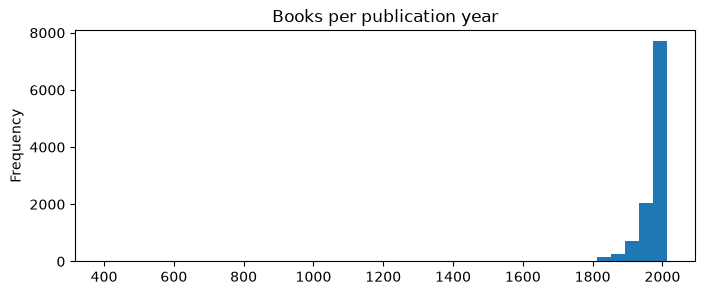


Top 10 authors by number of books:
author
Agatha Christie         74
Franklin W. Dixon       68
K. A. Applegate         62
Stephen King            60
Edgar Rice Burroughs    59
Ruth Rendell            55
John Dickson Carr       55
P. G. Wodehouse         50
Orson Scott Card        49
Harry Turtledove        49
Name: count, dtype: int64


In [52]:
df["year"] = pd.to_numeric(df["pub_date"].astype(str).str[:4], errors="coerce")

print(df["year"].describe().round(0))
df["year"].dropna().astype(int).plot.hist(bins=40, figsize=(8, 3), title="Books per publication year")
plt.show()

print("\nTop 10 authors by number of books:")
print(df["author"].value_counts().head(10))

### Duplicate titles

282 titles appear more than once. These are either different books sharing a title or the same book listed twice. They matter later because the reranker has to tell them apart.

In [53]:
dups = df[df["title"].duplicated(keep=False)].sort_values("title")
dups[["title", "author", "pub_date", "summary_words"]].head(12)

,title,author,pub_date,summary_words
7680,1945,William R. Forstchen,1995-08-01,446
10023,1945,Robert Conroy,2007-05-29,123
15495,A Casa,Miguel M. Abrahão,NaN,115
16330,A Casa,Andre Vianco,NaN,38
6653,A Taste for Death,Peter O'Donnell,NaN,256
9020,A Taste for Death,P. D. James,1986,54
5668,Abduction,Peg Kehret,2004-11,122
15682,Abduction,Robin Cook,2000,286
12061,American Beauty,Allen Steele,2006-09-06,165
13007,American Beauty,Edna Ferber,1931,227


### Findings so far

- Some summaries are leftover Wikipedia markup (`==Reception`, `pl:Zakochany golem`), not plot text.
- 58% of summaries are longer than 200 words, so a 256-token embedding model will not see the end of most plots.
- Titles are not unique (282 repeats are different books), so `wiki_id` is the row identifier.
- A few summaries are shared by several rows.
- Author (14%), date (34%) and genre (22%) are often missing. This does not block search, but the UI needs fallbacks.

Next we measure how widespread the markup and duplicate problems are, so the cleaning rules are based on data and not on guesses.

### How many summaries contain Wikipedia markup?

We count summaries that contain four typical markup patterns: section headings (`==`), language prefixes (`pl:`), wiki links (`[[`, `{{`) and HTML leftovers (`<ref`, `&nbsp;`).
                                                                                                                                      
                                                                                                            

In [54]:
import re

patterns = {
    "heading markup (==)": r"==",
    "language prefix (pl:)": r"^[a-z]{2,3}:",
    "wiki links ([[ or {{)": r"\[\[|\{\{",
    "html leftovers": r"<ref|<br|&nbsp;|&amp;",
}
for name, pat in patterns.items():
    mask = df["summary"].str.contains(pat, regex=True)
    print(f"{name:26} {mask.sum():>6} books")

has_heading = df["summary"].str.contains("==", regex=False)
df[has_heading][["title", "summary_words", "summary"]].sample(5, random_state=1)                                                                                                                           

heading markup (==)            48 books
language prefix (pl:)           0 books
wiki links ([[ or {{)           6 books
html leftovers                223 books


,title,summary_words,summary
12932,The Story of Edgar Sawtelle,7,=== What Hands Do Chequamegon Poison ===
8829,Kai Lung Unrolls His Mat,649,"Kai Lung adventures usually serve as mere excuses to bring up side stories along the way, which typically take up t..."
15671,Fear,451,"JJ, who works at a restaurant managed by Florian, meets with a group of kids hanging out at the parking lot of the ..."
14744,The Ghost-Seer,61,The work is narrated in the first person by the 'Graf von O**' (Count of O**). It describes the story of a German p...
1024,Oahspe: A New Bible,751,"Oahspe includes doctrinal books, and precepts for behavior can be found throughout its many books. Freedom and resp..."


### Duplicate summaries

Some rows share exactly the same summary text. If they are different books, that is a data error. If they are the same book listed twice, we should keep only one.

In [55]:
dup_sum = df[df["summary"].duplicated(keep=False)].sort_values("summary")
print(len(dup_sum), "rows share their summary with at least one other row")
dup_sum[["title", "author", "summary_words"]].head(10)

37 rows share their summary with at least one other row


,title,author,summary_words
5693,The Deathlord of Ixia,John Grant,1
5879,The Caverns of Kalte,Joe Dever,1
16531,Guardians of Ga'Hoole Book 4: The Siege,Helen Dunmore,1
11215,Chucaro: Wild Pony of the Pampa,Francis Kalnay,1
15789,Lurulu,Jack Vance,1
7817,Conviction,Richard North Patterson,11
10511,Nothing to Lose,Lee Child,11
13381,Beyond Thirty and The Man-Eater,Edgar Rice Burroughs,7
16161,The Oakdale Affair and The Rider,Edgar Rice Burroughs,7
6622,The Saint in Pursuit,Leslie Charteris,3


### Short but not empty: where to draw the line?

Summaries under 20 words are clearly broken. But what about 20 to 60 words? We read a random sample to decide whether they are real plot summaries.

In [56]:
mid = df[df["summary_words"].between(20, 60)]
print(len(mid), "books between 20 and 60 words")
mid.sample(8, random_state=1)[["title", "summary_words", "summary"]]

1318 books between 20 and 60 words


,title,summary_words,summary
6206,All-Consuming Fire,39,Sherlock Holmes finds himself united with the Seventh Doctor to solve the mystery of the theft of arcane tomes from...
8736,The Risk Pool,28,"The plot follows narrator Ned Hall through four periods of his life, focusing specifically on Hall's relationship w..."
13525,No One Thinks Of Greenland,30,The book is set after the Korean War. The novel follows the misadventures of the character Rudy Spruance who has be...
13069,Edith's Diary,53,"When Edith Howland's husband abandons her for a younger woman, leaving her with their alcoholic son and his senile ..."
3767,Julie of the Wolves,27,"The story has three parts, from her present situation (Amaroq, the Wolf), then a flashback (Miyax, the Girl), and f..."
14785,Wolf's Blood,35,"It is revealed here that Blind Seer is a Once Dead sorcerer himself, which explains his blue eyes. One of the twins..."
13347,A Writing Kind of Day,30,"A young writer's experiences are described in twenty seven mostly free verse poems. Topics included are roadkill, V..."
12612,Mutiny on the Enterprise,50,A much needed peace mission to the Orion Arm is delayed when the Enterprise becomes damaged while in orbit around a...


## 2. Cleaning

Decisions, based on the inspection above:

1. **Strip Wikipedia markup** from summaries: HTML tags, `{{templates}}`, `[[wiki links]]` (keeping the visible text), `==headings==`, and HTML entities such as `&amp;`.
2. **Drop summaries under 20 words.** The shortest ones are markup fragments (`==Receptio`), and 20 to 60 word summaries are real, if short, plot descriptions.
3. **Keep missing authors, dates and genres as missing.** They are not needed for search, and filling them with "Unknown" would put fake words into the search index. The UI will show a fallback instead.
4. **Use `wiki_id` as the row identifier**, because titles are not unique.

The original text is kept in `summary_raw` during cleaning, so we can compare before and after.

In [57]:
import html

def clean_summary(text):
    text = re.sub(r"<[^>]+>", " ", text)                           # html tags like <ref>, <br>
    text = re.sub(r"\{\{.*?\}\}", " ", text)                       # {{templates}}
    text = re.sub(r"\[\[(?:[^|\]]*\|)?([^\]]*)\]\]", r"\1", text)  # [[link|text]] -> text
    text = re.sub(r"={2,}[^=]{0,100}={2,}", " ", text)             # ==Heading==
    text = re.sub(r"={2,}", " ", text)                             # leftover == fragments
    text = html.unescape(text)                                     # &amp; -> &
    text = re.sub(r"<ref\b[^>]*$", " ", text, flags=re.IGNORECASE)  # malformed trailing ref tag
    return re.sub(r"\s+", " ", text).strip()

def context(text, pat, width=50):
    m = re.search(pat, text)
    return text[max(0, m.start() - width): m.end() + width] if m else ""

html_pat = r"<ref|<br|&nbsp;|&amp;"
wiki_pat = r"\[\[|\{\{"

df["summary_raw"] = df["summary"]

# look at the raw text around the markup before changing anything
print("--- html leftovers, before cleaning (5 random examples) ---")
for t in df[df["summary_raw"].str.contains(html_pat)].sample(5, random_state=1)["summary_raw"]:
    print("*", context(t, html_pat))

print("\n--- wiki links, before cleaning ---")
for t in df[df["summary_raw"].str.contains(wiki_pat)]["summary_raw"]:
    print("*", context(t, wiki_pat))

--- html leftovers, before cleaning (5 random examples) ---
* rmany. The biplane, with its top speed of just 103&nbsp;mph, is strafing the runways and destroying multim
* oks combined are estimated to have earned over $30&nbsp;million for Comic Relief. The two books have since
* el, where Stephen finds comfort in Barbara Berrill&nbsp;– a girl Stephen's age living in his neighbourhood
* ter him into accepting the offer (see "Quotes", p.&nbsp;163) - an attempt that doesn't work. The Prince ex
* and kills her. Most of the actors don't fight back&nbsp;— thinking this is a plot change&nbsp;— but soon r

--- wiki links, before cleaning ---
* i-lan has an older brother who has been living in [[United States for a few years. He has a friend wri
*  equal to its supply price.&#34; *Chapter 11. The [[marginal efficiency of capital]] *Chapter 12. The 
* ere is an abandoned one named The Grubber (an old [[English word for sweet shop) near where he lives. 
* ds to go back and witness Jackie Robinson

### Apply the cleaning and drop the broken rows

After cleaning, the word count is recomputed. This matters because a summary that is mostly markup can fall under the 20-word limit only after the markup is removed. Dropped rows are kept in `dropped` so nothing disappears without a record.

In [58]:
MIN_WORDS = 20

df["summary"] = df["summary_raw"].apply(clean_summary)
df["summary_words"] = df["summary"].str.split().str.len()

print("summaries changed by cleaning:", (df["summary"] != df["summary_raw"]).sum())

dropped = df[df["summary_words"] < MIN_WORDS]
df = df[df["summary_words"] >= MIN_WORDS].reset_index(drop=True)

print("dropped (under 20 words):", len(dropped))
print("remaining books:", len(df))

summaries changed by cleaning: 16555
dropped (under 20 words): 203
remaining books: 16356


### Check the result

Three checks: the markup patterns should be gone, the shortest remaining summaries should be real text, and we count the duplicate summaries again.

In [59]:
for name, pat in {"headings": r"==", "html": html_pat, "wiki links": wiki_pat}.items():
    print(f"{name:12} remaining: {df['summary'].str.contains(pat).sum()}")

print("\nduplicate summaries now:", df["summary"].duplicated(keep=False).sum(), "rows")
print("\nshortest remaining summaries:")
df.nsmallest(5, "summary_words")[["title", "author", "summary_words", "summary"]]

headings     remaining: 0
html         remaining: 0
wiki links   remaining: 5

duplicate summaries now: 0 rows

shortest remaining summaries:


,title,author,summary_words,summary
1303,"A Child Called ""It""",Dave Pelzer,20,The book is written as a memoir which covers physical and emotional abuse between Dave Pelzer and his biological mot...
3227,The Secret of Wildcat Swamp,Franklin W. Dixon,20,An paleontology expedition in the West turns into a desperate attempt to capture freight train robbers and an escape...
5684,The Witch Hunters,Steve Lyons,20,"In Salem Village, Massachusetts, 1692, the Doctor and his companions become immeshed in the tragedy of the Salem wit..."
6505,No Future,Paul Cornell,20,"London, 1976, while Bernice becomes lead singer in a punk band, the Doctor must face more than one old enemy..."
6538,Revolution Man,Paul Leonard,20,The Doctor tries to stop a mysterious entity called The Revolution Man from spreading mind altering drugs in the 1960s.


### Sanity checks on the cleaning

Two things to verify:
- Nearly every summary was reported as "changed". We check how many changed by more than whitespace. If the answer is a few hundred, the cleaning only touched what it should.
- A handful of malformed wiki links (`[[United States` with no closing brackets) and one html match survived. We look at the html match, then remove leftover `[[` and `]]` characters.

In [60]:
collapse_ws = lambda s: re.sub(r"\s+", " ", s).strip()

changed_beyond_ws = df["summary"] != df["summary_raw"].apply(collapse_ws)
print("changed beyond whitespace:", changed_beyond_ws.sum())

print("\nremaining html match:")
for t in df[df["summary"].str.contains(html_pat)]["summary"]:
    print("*", context(t, html_pat))

changed beyond whitespace: 916

remaining html match:


In [61]:
def clean_summary(text):
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\{\{.*?\}\}", " ", text)
    text = re.sub(r"\[\[(?:[^|\]]*\|)?([^\]]*)\]\]", r"\1", text)
    text = re.sub(r"={2,}[^=]{0,100}={2,}", " ", text)
    text = re.sub(r"={2,}", " ", text)
    text = html.unescape(text)
    text = re.sub(r"<ref\b[^>]*$", " ", text, flags=re.IGNORECASE)  # malformed trailing ref tag
    text = text.replace("[[", "").replace("]]", "")   # malformed leftovers
    return re.sub(r"\s+", " ", text).strip()

df["summary"] = df["summary_raw"].apply(clean_summary)
df["summary_words"] = df["summary"].str.split().str.len()

print("rows now under 20 words:", (df["summary_words"] < MIN_WORDS).sum())
print("wiki-link leftovers:", df["summary"].str.contains(r"\[\[|\]\]").sum())
print("html leftovers:", df["summary"].str.contains(html_pat).sum())
print("remaining books:", len(df))

rows now under 20 words: 0
wiki-link leftovers: 0
html leftovers: 0
remaining books: 16356


### Save the cleaned dataset

The cleaned table is saved as a Parquet file (compact, keeps column types). The raw download stays out of git, but this cleaned file is committed, so anyone can reproduce the results without re-running the cleaning.

In [62]:
OUT = ROOT / "data/processed/books_clean.parquet"
OUT.parent.mkdir(parents=True, exist_ok=True)

cols = ["wiki_id", "title", "author", "pub_date", "genres", "summary", "summary_words"]
df[cols].to_parquet(OUT, index=False)

print(f"saved {len(df)} books, {OUT.stat().st_size / 1e6:.1f} MB")

saved 16356 books, 26.0 MB


## 3. BM25 baseline

This is the first retrieval baseline. It indexes the title, author and cleaned plot summary together, with no title boost yet. Every query in `data/processed/queries.csv` is searched against the same cleaned corpus. The index and per-query results are saved under `data/processed/` so the run can be inspected and repeated.

Before running this section, install the project dependencies from the repository root with `pip install -r requirements.txt`.

In [63]:
import time
import bm25s

QUERY_PATH = ROOT / "data/processed/queries.csv"
INDEX_PATH = ROOT / "data/processed/bm25_index"
RESULTS_PATH = ROOT / "data/processed/bm25_results.csv"

queries = pd.read_csv(QUERY_PATH, dtype={"gold_wiki_id": str})
queries["gold_wiki_id"] = queries["gold_wiki_id"].str.strip()

# Keep this row order unchanged: retrieved BM25 document IDs are row positions.
df["wiki_id"] = df["wiki_id"].astype(str)
df["bm25_text"] = (
    df[["title", "author", "summary"]]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
corpus = df["bm25_text"].tolist()

print("books:", len(corpus))
print("queries:", len(queries))
print("query groups:")
print(queries["group"].value_counts())
print("gold IDs missing from corpus:", (~queries["gold_wiki_id"].isin(df["wiki_id"])).sum())

books: 16356
queries: 60
query groups:
group
exact_words        20
vague_plot         20
near_duplicates    20
Name: count, dtype: int64
gold IDs missing from corpus: 0


In [64]:
# Tokenize and build a BM25 index over all cleaned books.
corpus_tokens = bm25s.tokenize(corpus)
retriever = bm25s.BM25()
retriever.index(corpus_tokens)

# Save only the sparse index; book metadata is loaded from the Parquet table.
retriever.save(str(INDEX_PATH))
print("saved BM25 index to:", INDEX_PATH)

saved BM25 index to: /Users/shreyas/Desktop/THWS/2nd sem/NLP/Portfolio 2/data/processed/bm25_index


### Inspect raw BM25 results before interpreting the metrics

Read these examples first. The gold book is shown for diagnosis only; the search function itself does not use gold labels. Check whether the returned books make sense and note patterns such as exact-name matches, generic plot matches, and near-duplicate series entries.

In [65]:
TOP_K = 10
result_rows = []

for _, qrow in queries.iterrows():
    started = time.perf_counter()
    query_tokens = bm25s.tokenize(qrow["query"])
    doc_ids, scores = retriever.retrieve(query_tokens, k=TOP_K)
    elapsed_ms = (time.perf_counter() - started) * 1000

    ranked_ids = doc_ids[0].astype(int).tolist()
    ranked_scores = scores[0].astype(float).tolist()
    gold_row = df.index[df["wiki_id"] == qrow["gold_wiki_id"]][0]
    gold_rank = ranked_ids.index(int(gold_row)) + 1 if int(gold_row) in ranked_ids else None

    for rank, (doc_id, score) in enumerate(zip(ranked_ids, ranked_scores), start=1):
        book = df.iloc[doc_id]
        result_rows.append({
            "query": qrow["query"],
            "group": qrow["group"],
            "gold_wiki_id": qrow["gold_wiki_id"],
            "gold_rank": gold_rank,
            "rank": rank,
            "wiki_id": book["wiki_id"],
            "title": book["title"],
            "author": book["author"],
            "bm25_score": score,
            "latency_ms": elapsed_ms,
        })

bm25_results = pd.DataFrame(result_rows)
bm25_results.to_csv(RESULTS_PATH, index=False)
print("saved ranked results to:", RESULTS_PATH)

# Show two complete ranked lists from each group before looking at aggregate scores.
for group in queries["group"].drop_duplicates():
    print(f"\n### {group}")
    examples = queries.loc[queries["group"] == group].head(2)
    for _, qrow in examples.iterrows():
        ranks = bm25_results[bm25_results["query"] == qrow["query"]].sort_values("rank")
        gold = df.loc[df["wiki_id"] == qrow["gold_wiki_id"], "title"].iloc[0]
        print(f"\nQuery: {qrow['query']}\nGold: {gold} (rank {ranks['gold_rank'].iloc[0]})")
        display(ranks[["rank", "title", "author", "bm25_score"]])

saved ranked results to: /Users/shreyas/Desktop/THWS/2nd sem/NLP/Portfolio 2/data/processed/bm25_results.csv

### exact_words

Query: Bilbo Baggins, the One Ring, and Smaug at the Lonely Mountain
Gold: The Hobbit (rank 1.0)


,rank,title,author,bm25_score
0,1,The Hobbit,J. R. R. Tolkien,21.359032
1,2,The Fellowship of the Ring,J. R. R. Tolkien,13.759390
2,3,The Lord of the Rings,J. R. R. Tolkien,11.347618
3,4,The Lord of the Rings,Shaun McKenna,10.448159
4,5,The Return of the King,J. R. R. Tolkien,9.601251
5,6,Ringworld,Larry Niven,5.609804
6,7,Marazan,Nevil Shute,4.622087
7,8,Swan Song,Robert R. McCammon,4.125676
8,9,The Tombs of Atuan,Ursula K. Le Guin,4.117733
9,10,Thunderspire Labyrinth,NaN,4.003607



Query: Elizabeth Bennet, Mr Darcy, and the five Bennet sisters
Gold: Pride and Prejudice (rank 2.0)


,rank,title,author,bm25_score
10,1,Pride and Prejudice and Zombies,NaN,22.004744
11,2,Pride and Prejudice,Jane Austen,21.230928
12,3,Death Comes to Pemberley,P. D. James,20.245451
13,4,These Three Remain,Pamela Aidan,19.200661
14,5,An Assembly Such as This,Pamela Aidan,18.837204
15,6,"Love, Lies and Lizzie",NaN,18.662930
16,7,Duty and Desire,Pamela Aidan,17.108978
17,8,Pride and Prejudice and Zombies: Dawn of the Dreadfuls,Steve Hockensmith,15.131537
18,9,OtherSpace,NaN,10.691021
19,10,An Instance of the Fingerpost,Iain Pears,9.278263



### vague_plot

Query: Farmyard creatures overthrow their human owner, then a ruling clique becomes just as oppressive
Gold: Animal Farm (rank nan)


,rank,title,author,bm25_score
200,1,The Ruling Class,Francine Pascal,8.681128
201,2,The Whisperer,Fiona McIntosh,5.653699
202,3,Thorn Ogres of Hagwood,Robin Jarvis,5.451729
203,4,Expecting Someone Taller,Tom Holt,5.076475
204,5,Blindness,José Saramago,4.996730
205,6,Forty Thousand in Gehenna,C. J. Cherryh,4.805195
206,7,A Deepness in the Sky,Vernor Vinge,4.802291
207,8,Cat's Cradle: Witchmark,NaN,4.741076
208,9,Beyond the Nightmare Gate,Ian Page,4.733057
209,10,The Game-Players of Titan,Philip K. Dick,4.634292


... (2 outputs left out)


### near_duplicates

Query: A newspaper art reporter rents a room from a one-handed critic and investigates the death of an artist; his backward-reading Siamese is involved
Gold: The Cat Who Could Read Backwards (rank 1.0)


,rank,title,author,bm25_score
400,1,The Cat Who Could Read Backwards,Lilian Jackson Braun,15.821759
401,2,What a carve up!,Jonathan Coe,7.667672
402,3,Amnesiascope,Steve Erickson,7.595626
403,4,After the Funeral,Agatha Christie,7.264555
404,5,The Last Coyote,Michael Connelly,7.099432
405,6,The Flame Breathers,NaN,6.933246
406,7,An Age,Brian Aldiss,6.805063
407,8,La Carte et le territoire,Michel Houellebecq,6.804641
408,9,Old Masters,Thomas Bernhard,6.801013
409,10,Wycliffe and the Winsor Blue,W. J. Burley,6.681085



Query: An interior-design assignment leads a reporter to a jade-collecting couple, a robbed mansion, and a death
Gold: The Cat Who Ate Danish Modern (rank 1.0)


,rank,title,author,bm25_score
410,1,The Cat Who Ate Danish Modern,Lilian Jackson Braun,14.761126
411,2,Vicky Angel,Jacqueline Wilson,6.294158
412,3,O Dinheiro,Miguel M. Abrahão,6.251631
413,4,Fourth Mansions,R. A. Lafferty,6.171384
414,5,The Mystery at Devil's Paw,Franklin W. Dixon,5.441993
415,6,Trent's Last Case,E. C. Bentley,5.352432
416,7,The prophecy of the stones,Flavia Bujor,5.307536
417,8,"Bribery, Corruption Also",H. R. F. Keating,5.197458
418,9,Cause of Death,Patricia Cornwell,5.158675
419,10,The Glass Inferno,Thomas N. Scortia,4.920628


### Recall@10 and MRR by query group

With one gold book per query, Recall@10 is the fraction of queries whose gold book appears in the first ten results. MRR is the mean reciprocal rank of the gold book (zero when it is not retrieved). We also report average and median query latency for this local baseline; these timings depend on the machine and should not be treated as hosted-service latency.

In [66]:
per_query = (
    bm25_results.groupby(["query", "group", "gold_wiki_id"], as_index=False)
    .agg(gold_rank=("gold_rank", "first"), latency_ms=("latency_ms", "first"))
)
per_query["recall_at_10"] = per_query["gold_rank"].notna().astype(float)
per_query["reciprocal_rank"] = per_query["gold_rank"].map(
    lambda rank: 1.0 / rank if pd.notna(rank) else 0.0
)

bm25_metrics = (
    per_query.groupby("group")
    .agg(
        queries=("query", "count"),
        recall_at_10=("recall_at_10", "mean"),
        mrr=("reciprocal_rank", "mean"),
        mean_latency_ms=("latency_ms", "mean"),
        median_latency_ms=("latency_ms", "median"),
    )
    .round(3)
)
all_metrics = pd.DataFrame([{
    "queries": len(per_query),
    "recall_at_10": per_query["recall_at_10"].mean(),
    "mrr": per_query["reciprocal_rank"].mean(),
    "mean_latency_ms": per_query["latency_ms"].mean(),
    "median_latency_ms": per_query["latency_ms"].median(),
}], index=["ALL"])
bm25_metrics = pd.concat([bm25_metrics, all_metrics]).round(3)


## 4. Dense search

Now we compare semantic retrieval with the BM25 baseline using the same 60 queries and gold IDs. The encoder embeds each cleaned plot summary once. At query time, we embed the query and rank the summaries by cosine similarity, computed as a dot product of normalized vectors.

This first pass uses `sentence-transformers/all-MiniLM-L6-v2`. Its input limit means long plots are truncated; the summary-length inspection above shows this may affect results. Keep that limitation in mind when reading failures. The corpus vectors are cached in `data/processed/` and reused when the model and corpus have not changed.

Install the added dependency with `pip install -r requirements.txt` before running these cells. The first run downloads the model.

In [67]:
import hashlib
import numpy as np
from sentence_transformers import SentenceTransformer

MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
EMBEDDINGS_PATH = ROOT / "data/processed/book_embeddings.npy"
EMBEDDINGS_META_PATH = ROOT / "data/processed/book_embeddings_meta.json"

# Include title and author as well as the plot so dense search can find books
# from author-name queries. The same text is used in the embedding cache key.
summary_texts = (
    df[["title", "author", "summary"]]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
    .tolist()
)
corpus_fingerprint = hashlib.sha256(
    "\n".join(df["wiki_id"].astype(str).tolist()).encode("utf-8")
    + b"\0"
    + "\n".join(summary_texts).encode("utf-8")
).hexdigest()

model = SentenceTransformer(MODEL_NAME)
print("model:", MODEL_NAME)
print("model max sequence length:", model.max_seq_length)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 10023.28it/s]


model: sentence-transformers/all-MiniLM-L6-v2
model max sequence length: 256


In [68]:
cache_is_valid = False
if EMBEDDINGS_PATH.exists() and EMBEDDINGS_META_PATH.exists():
    cached_meta = json.loads(EMBEDDINGS_META_PATH.read_text(encoding="utf-8"))
    cache_is_valid = (
        cached_meta.get("model_name") == MODEL_NAME
        and cached_meta.get("corpus_fingerprint") == corpus_fingerprint
    )

if cache_is_valid:
    book_embeddings = np.load(EMBEDDINGS_PATH)
    if book_embeddings.shape[0] != len(df):
        cache_is_valid = False

if not cache_is_valid:
    print("Encoding book summaries; this may take a few minutes on CPU.")
    book_embeddings = model.encode(
        summary_texts,
        batch_size=64,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True,
    ).astype(np.float32)
    np.save(EMBEDDINGS_PATH, book_embeddings)
    EMBEDDINGS_META_PATH.write_text(
        json.dumps({
            "model_name": MODEL_NAME,
            "corpus_fingerprint": corpus_fingerprint,
            "number_of_books": len(df),
            "embedding_dimension": int(book_embeddings.shape[1]),
        }, indent=2) + "\n",
        encoding="utf-8",
    )
    print("saved embeddings to:", EMBEDDINGS_PATH)
else:
    print("loaded cached embeddings from:", EMBEDDINGS_PATH)

print("embedding matrix:", book_embeddings.shape, book_embeddings.dtype)
print("first vector norm:", round(float(np.linalg.norm(book_embeddings[0])), 4))

loaded cached embeddings from: /Users/shreyas/Desktop/THWS/2nd sem/NLP/Portfolio 2/data/processed/book_embeddings.npy
embedding matrix: (16356, 384) float32
first vector norm: 1.0


### Retrieve and inspect dense results

Each latency measurement includes encoding the query and scoring it against all 16k book vectors. It excludes the one-time corpus embedding step. The raw ranked lists are saved so failures can be inspected before relying on the aggregate metrics.

In [69]:
DENSE_TOP_K = 10
dense_result_rows = []

for _, qrow in queries.iterrows():
    started = time.perf_counter()
    query_embedding = model.encode(
        [qrow["query"]],
        convert_to_numpy=True,
        normalize_embeddings=True,
    )[0]
    scores = book_embeddings @ query_embedding
    candidate_ids = np.argpartition(scores, -DENSE_TOP_K)[-DENSE_TOP_K:]
    ranked_ids = candidate_ids[np.argsort(scores[candidate_ids])[::-1]]
    elapsed_ms = (time.perf_counter() - started) * 1000

    gold_rows = np.flatnonzero(df["wiki_id"].to_numpy() == qrow["gold_wiki_id"])
    if len(gold_rows) != 1:
        raise ValueError(f"Expected one corpus row for gold wiki_id {qrow['gold_wiki_id']}")
    gold_row = int(gold_rows[0])
    gold_rank = int(np.where(ranked_ids == gold_row)[0][0]) + 1 if gold_row in ranked_ids else None

    for rank, doc_id in enumerate(ranked_ids, start=1):
        book = df.iloc[int(doc_id)]
        dense_result_rows.append({
            "query": qrow["query"],
            "group": qrow["group"],
            "gold_wiki_id": qrow["gold_wiki_id"],
            "gold_rank": gold_rank,
            "rank": rank,
            "wiki_id": book["wiki_id"],
            "title": book["title"],
            "author": book["author"],
            "dense_score": float(scores[int(doc_id)]),
            "latency_ms": elapsed_ms,
        })

dense_results = pd.DataFrame(dense_result_rows)
DENSE_RESULTS_PATH = ROOT / "data/processed/dense_results.csv"
dense_results.to_csv(DENSE_RESULTS_PATH, index=False)
print("saved ranked results to:", DENSE_RESULTS_PATH)

for group in queries["group"].drop_duplicates():
    print(f"\n### {group}")
    for _, qrow in queries.loc[queries["group"] == group].head(2).iterrows():
        ranks = dense_results[dense_results["query"] == qrow["query"]].sort_values("rank")
        gold_title = df.loc[df["wiki_id"] == qrow["gold_wiki_id"], "title"].iloc[0]
        print(f"\nQuery: {qrow['query']}\nGold: {gold_title} (rank {ranks['gold_rank'].iloc[0]})")
        display(ranks[["rank", "title", "author", "dense_score"]])

saved ranked results to: /Users/shreyas/Desktop/THWS/2nd sem/NLP/Portfolio 2/data/processed/dense_results.csv

### exact_words

Query: Bilbo Baggins, the One Ring, and Smaug at the Lonely Mountain
Gold: The Hobbit (rank 3.0)


,rank,title,author,dense_score
0,1,The Lord of the Rings,Shaun McKenna,0.637894
1,2,The Fellowship of the Ring,J. R. R. Tolkien,0.589644
2,3,The Hobbit,J. R. R. Tolkien,0.573695
3,4,The Lord of the Rings,J. R. R. Tolkien,0.549777
4,5,"The 35th of May, or Conrad's Ride to the South Seas",Erich Kästner,0.488898
5,6,Savage Pellucidar,Edgar Rice Burroughs,0.411952
6,7,The Last Ringbearer,Kirill Yeskov,0.404803
7,8,The Mountain Is Young,Han Suyin,0.401820
8,9,The Warlord of Mars,Edgar Rice Burroughs,0.391708
9,10,The Covent Garden Tragedy,Henry Fielding,0.391065



Query: Elizabeth Bennet, Mr Darcy, and the five Bennet sisters
Gold: Pride and Prejudice (rank 2.0)


,rank,title,author,dense_score
10,1,An Assembly Such as This,Pamela Aidan,0.662417
11,2,Pride and Prejudice,Jane Austen,0.661625
12,3,Death Comes to Pemberley,P. D. James,0.615319
13,4,"Love, Lies and Lizzie",NaN,0.610940
14,5,Duty and Desire,Pamela Aidan,0.610135
15,6,These Three Remain,Pamela Aidan,0.601933
16,7,Searching for David's Heart,Cherie Bennett,0.537738
17,8,Pride and Prejudice and Zombies,NaN,0.497997
18,9,Autumn Street,Lois Lowry,0.470940
19,10,The Reluctant Queen: The Story of Anne of York,Eleanor Hibbert,0.470041



### vague_plot

Query: Farmyard creatures overthrow their human owner, then a ruling clique becomes just as oppressive
Gold: Animal Farm (rank nan)


,rank,title,author,dense_score
200,1,Malevil,Robert Merle,0.422767
201,2,City,Clifford D. Simak,0.408256
202,3,Jack the Hare and Mukuyu Forest,NaN,0.407907
203,4,Snowball's Chance,John Reed,0.406939
204,5,The Sheep-Pig,Dick King-Smith,0.405074
205,6,Running with the Demon,Terry Brooks,0.397192
206,7,Cold Comfort Farm,Stella Gibbons,0.393784
207,8,Aunt Phillis's Cabin,Seth Eastman,0.391548
208,9,The Late Lancashire Witches,Thomas Heywood,0.388870
209,10,Half Past Human,T. J. Bass,0.385143


... (2 outputs left out)


### near_duplicates

Query: A newspaper art reporter rents a room from a one-handed critic and investigates the death of an artist; his backward-reading Siamese is involved
Gold: The Cat Who Could Read Backwards (rank nan)


,rank,title,author,dense_score
400,1,Travels in the Scriptorium,Paul Auster,0.457243
401,2,The Haunted Bookshop,Christopher Morley,0.439074
402,3,Hygiene and the Assassin,Amélie Nothomb,0.435821
403,4,The Incendiary's Trail,James McCreet,0.431863
404,5,The Greek Coffin Mystery,Frederic Dannay,0.430127
405,6,Room One,Andrew Clements,0.423206
406,7,Time's Arrow,Martin Amis,0.416069
407,8,Talkative Man,R. K. Narayan,0.407180
408,9,The Hollow Man,John Dickson Carr,0.405170
409,10,The Glass Cafe,Gary Paulsen,0.400544



Query: An interior-design assignment leads a reporter to a jade-collecting couple, a robbed mansion, and a death
Gold: The Cat Who Ate Danish Modern (rank nan)


,rank,title,author,dense_score
410,1,Dead Famous,Ben Elton,0.482234
411,2,The Wedding Day Mystery,NaN,0.480377
412,3,All That Remains,Patricia Cornwell,0.448151
413,4,The Hidden Child,Camilla Läckberg,0.445468
414,5,The House,Danielle Steel,0.443831
415,6,Die Dame im Chinchilla,NaN,0.442726
416,7,The Amber Room,Steve Berry,0.439950
417,8,The Plague Court Murders,John Dickson Carr,0.438280
418,9,The Crooked Banister,Carolyn Keene,0.437482
419,10,In the Country of Last Things,Paul Auster,0.435516


### Dense metrics by group

These metrics use the same definitions as the BM25 baseline. Compare the group rows side by side; a higher Recall@10 or MRR is evidence for that method on this query set, not a guarantee that it will win on other queries.

In [70]:
dense_per_query = (
    dense_results.groupby(["query", "group", "gold_wiki_id"], as_index=False)
    .agg(gold_rank=("gold_rank", "first"), latency_ms=("latency_ms", "first"))
)
dense_per_query["recall_at_10"] = dense_per_query["gold_rank"].notna().astype(float)
dense_per_query["reciprocal_rank"] = dense_per_query["gold_rank"].map(
    lambda rank: 1.0 / rank if pd.notna(rank) else 0.0
)

dense_metrics = (
    dense_per_query.groupby("group")
    .agg(
        queries=("query", "count"),
        recall_at_10=("recall_at_10", "mean"),
        mrr=("reciprocal_rank", "mean"),
        mean_latency_ms=("latency_ms", "mean"),
        median_latency_ms=("latency_ms", "median"),
    )
    .round(3)
)
dense_total = pd.DataFrame([{
    "queries": len(dense_per_query),
    "recall_at_10": dense_per_query["recall_at_10"].mean(),
    "mrr": dense_per_query["reciprocal_rank"].mean(),
    "mean_latency_ms": dense_per_query["latency_ms"].mean(),
    "median_latency_ms": dense_per_query["latency_ms"].median(),
}], index=["ALL"])
dense_metrics = pd.concat([dense_metrics, dense_total]).round(3)
dense_metrics

,queries,recall_at_10,mrr,mean_latency_ms,median_latency_ms
exact_words,20,1.000,0.804,15.816,5.119
near_duplicates,20,0.250,0.122,4.211,4.170
vague_plot,20,0.350,0.206,4.542,4.374
ALL,60,0.533,0.377,8.190,4.465


## 5. Chunked dense search experiment

The first dense run embeds one long summary per book. The encoder limits each input to 256 tokens, so later plot details can be discarded. Here we split each summary into overlapping 160-word chunks (about 200 tokens for typical English text), embed every chunk, and give each book its best matching chunk score.

This is an experiment, not a replacement of the first dense baseline: the two dense runs use the same model and query set, so we can see whether chunking helps. Chunk vectors are cached separately.

In [71]:
CHUNK_WORDS = 160
CHUNK_OVERLAP_WORDS = 30
CHUNK_EMBEDDINGS_PATH = ROOT / "data/processed/book_chunk_embeddings.npy"
CHUNK_BOOK_IDS_PATH = ROOT / "data/processed/book_chunk_to_book.npy"
CHUNK_META_PATH = ROOT / "data/processed/book_chunk_embeddings_meta.json"

def split_summary(text, chunk_words=CHUNK_WORDS, overlap_words=CHUNK_OVERLAP_WORDS):
    words = str(text).split()
    if not words:
        return [""]
    chunks = []
    start = 0
    while start < len(words):
        end = min(start + chunk_words, len(words))
        chunks.append(" ".join(words[start:end]))
        if end == len(words):
            break
        start = end - overlap_words
    return chunks

chunk_texts = []
chunk_book_ids = []
for book_id, summary in enumerate(summary_texts):
    book_chunks = split_summary(summary)
    chunk_texts.extend(book_chunks)
    chunk_book_ids.extend([book_id] * len(book_chunks))
chunk_book_ids = np.asarray(chunk_book_ids, dtype=np.int32)

chunk_meta_expected = {
    "model_name": MODEL_NAME,
    "corpus_fingerprint": corpus_fingerprint,
    "chunk_words": CHUNK_WORDS,
    "overlap_words": CHUNK_OVERLAP_WORDS,
}
print("book summaries:", len(summary_texts))
print("summary chunks:", len(chunk_texts))
print("average chunks per book:", round(len(chunk_texts) / len(df), 2))

book summaries: 16356
summary chunks: 59500
average chunks per book: 3.64


In [72]:
chunk_cache_valid = False
if CHUNK_EMBEDDINGS_PATH.exists() and CHUNK_BOOK_IDS_PATH.exists() and CHUNK_META_PATH.exists():
    cached_chunk_meta = json.loads(CHUNK_META_PATH.read_text(encoding="utf-8"))
    chunk_cache_valid = all(
        cached_chunk_meta.get(key) == value
        for key, value in chunk_meta_expected.items()
    )

if chunk_cache_valid:
    chunk_embeddings = np.load(CHUNK_EMBEDDINGS_PATH)
    cached_book_ids = np.load(CHUNK_BOOK_IDS_PATH)
    chunk_cache_valid = (
        len(chunk_embeddings) == len(chunk_texts)
        and np.array_equal(cached_book_ids, chunk_book_ids)
    )

if not chunk_cache_valid:
    print("Encoding summary chunks; the first run may take several minutes on CPU.")
    chunk_embeddings = model.encode(
        chunk_texts,
        batch_size=64,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True,
    ).astype(np.float32)
    np.save(CHUNK_EMBEDDINGS_PATH, chunk_embeddings)
    np.save(CHUNK_BOOK_IDS_PATH, chunk_book_ids)
    chunk_meta_expected["number_of_chunks"] = len(chunk_texts)
    chunk_meta_expected["embedding_dimension"] = int(chunk_embeddings.shape[1])
    CHUNK_META_PATH.write_text(
        json.dumps(chunk_meta_expected, indent=2) + "\n",
        encoding="utf-8",
    )
    print("saved chunk embeddings to:", CHUNK_EMBEDDINGS_PATH)
else:
    print("loaded cached chunk embeddings from:", CHUNK_EMBEDDINGS_PATH)

print("chunk embedding matrix:", chunk_embeddings.shape, chunk_embeddings.dtype)

loaded cached chunk embeddings from: /Users/shreyas/Desktop/THWS/2nd sem/NLP/Portfolio 2/data/processed/book_chunk_embeddings.npy
chunk embedding matrix: (59500, 384) float32


### Score each book by its best chunk

For each query, we encode the query once, score it against all chunk vectors, and take the maximum score for each book. We then rank books by that score and save the top ten. Per-query latency includes query encoding, chunk scoring and aggregation, but excludes one-time chunk encoding.

In [73]:
chunked_result_rows = []

for _, qrow in queries.iterrows():
    started = time.perf_counter()
    query_embedding = model.encode(
        [qrow["query"]],
        convert_to_numpy=True,
        normalize_embeddings=True,
    )[0]
    chunk_scores = chunk_embeddings @ query_embedding
    book_scores = np.full(len(df), -np.inf, dtype=np.float32)
    np.maximum.at(book_scores, chunk_book_ids, chunk_scores)
    candidate_ids = np.argpartition(book_scores, -DENSE_TOP_K)[-DENSE_TOP_K:]
    ranked_ids = candidate_ids[np.argsort(book_scores[candidate_ids])[::-1]]
    elapsed_ms = (time.perf_counter() - started) * 1000

    gold_rows = np.flatnonzero(df["wiki_id"].to_numpy() == qrow["gold_wiki_id"])
    if len(gold_rows) != 1:
        raise ValueError(f"Expected one corpus row for gold wiki_id {qrow['gold_wiki_id']}")
    gold_row = int(gold_rows[0])
    gold_rank = int(np.where(ranked_ids == gold_row)[0][0]) + 1 if gold_row in ranked_ids else None

    for rank, doc_id in enumerate(ranked_ids, start=1):
        book = df.iloc[int(doc_id)]
        chunked_result_rows.append({
            "query": qrow["query"],
            "group": qrow["group"],
            "gold_wiki_id": qrow["gold_wiki_id"],
            "gold_rank": gold_rank,
            "rank": rank,
            "wiki_id": book["wiki_id"],
            "title": book["title"],
            "author": book["author"],
            "dense_chunk_score": float(book_scores[int(doc_id)]),
            "latency_ms": elapsed_ms,
        })

chunked_results = pd.DataFrame(chunked_result_rows)
CHUNKED_RESULTS_PATH = ROOT / "data/processed/dense_chunked_results.csv"
chunked_results.to_csv(CHUNKED_RESULTS_PATH, index=False)
print("saved ranked results to:", CHUNKED_RESULTS_PATH)

for group in queries["group"].drop_duplicates():
    print(f"\n### {group}")
    for _, qrow in queries.loc[queries["group"] == group].head(2).iterrows():
        ranks = chunked_results[chunked_results["query"] == qrow["query"]].sort_values("rank")
        gold_title = df.loc[df["wiki_id"] == qrow["gold_wiki_id"], "title"].iloc[0]
        print(f"\nQuery: {qrow['query']}\nGold: {gold_title} (rank {ranks['gold_rank'].iloc[0]})")
        display(ranks[["rank", "title", "author", "dense_chunk_score"]])

saved ranked results to: /Users/shreyas/Desktop/THWS/2nd sem/NLP/Portfolio 2/data/processed/dense_chunked_results.csv

### exact_words

Query: Bilbo Baggins, the One Ring, and Smaug at the Lonely Mountain
Gold: The Hobbit (rank 3.0)


,rank,title,author,dense_chunk_score
0,1,The Lord of the Rings,Shaun McKenna,0.614564
1,2,The Lord of the Rings,J. R. R. Tolkien,0.606588
2,3,The Hobbit,J. R. R. Tolkien,0.571874
3,4,The Fellowship of the Ring,J. R. R. Tolkien,0.546648
4,5,"The 35th of May, or Conrad's Ride to the South Seas",Erich Kästner,0.479304
5,6,The Return of the King,J. R. R. Tolkien,0.451231
6,7,Dragonseye,Anne McCaffrey,0.429828
7,8,The Wandering Fire,Guy Gavriel Kay,0.428108
8,9,The Colour of Magic,Terry Pratchett,0.422363
9,10,The Last Ringbearer,Kirill Yeskov,0.414050



Query: Elizabeth Bennet, Mr Darcy, and the five Bennet sisters
Gold: Pride and Prejudice (rank 2.0)


,rank,title,author,dense_chunk_score
10,1,Pride and Prejudice and Zombies,NaN,0.732477
11,2,Pride and Prejudice,Jane Austen,0.685913
12,3,These Three Remain,Pamela Aidan,0.665968
13,4,An Assembly Such as This,Pamela Aidan,0.664739
14,5,Death Comes to Pemberley,P. D. James,0.615319
15,6,"Love, Lies and Lizzie",NaN,0.610940
16,7,Duty and Desire,Pamela Aidan,0.583189
17,8,An Instance of the Fingerpost,Iain Pears,0.566760
18,9,Searching for David's Heart,Cherie Bennett,0.537738
19,10,Pride and Prejudice and Zombies: Dawn of the Dreadfuls,Steve Hockensmith,0.492089



### vague_plot

Query: Farmyard creatures overthrow their human owner, then a ruling clique becomes just as oppressive
Gold: Animal Farm (rank nan)


,rank,title,author,dense_chunk_score
200,1,Gulliver's Travels,Jonathan Swift,0.472188
201,2,Snowball's Chance,John Reed,0.461728
202,3,Zoo City,Lauren Beukes,0.450614
203,4,My Ishmael,Daniel Quinn,0.447135
204,5,The Lost World,Michael Crichton,0.444831
205,6,Ascending,James Alan Gardner,0.430141
206,7,Mankind in Transition,NaN,0.426768
207,8,Hothouse,Brian Aldiss,0.424628
208,9,The Book of Sorrows,NaN,0.423513
209,10,Remnant Population,Elizabeth Moon,0.421859


... (2 outputs left out)


### near_duplicates

Query: A newspaper art reporter rents a room from a one-handed critic and investigates the death of an artist; his backward-reading Siamese is involved
Gold: The Cat Who Could Read Backwards (rank nan)


,rank,title,author,dense_chunk_score
400,1,The Landry News,Andrew Clements,0.450099
401,2,The Witch of the Low Tide,John Dickson Carr,0.442274
402,3,Travels in the Scriptorium,Paul Auster,0.440451
403,4,Hygiene and the Assassin,Amélie Nothomb,0.436470
404,5,The Incendiary's Trail,James McCreet,0.431863
405,6,The Haunted Bookshop,Christopher Morley,0.431837
406,7,Maus,Art Spiegelman,0.430480
407,8,Time's Arrow,Martin Amis,0.428401
408,9,The Greek Coffin Mystery,Frederic Dannay,0.425197
409,10,Room One,Andrew Clements,0.423206



Query: An interior-design assignment leads a reporter to a jade-collecting couple, a robbed mansion, and a death
Gold: The Cat Who Ate Danish Modern (rank nan)


,rank,title,author,dense_chunk_score
410,1,Dead Famous,Ben Elton,0.514415
411,2,The English Assassin,Daniel Silva,0.482502
412,3,The Chinese Orange Mystery,Frederic Dannay,0.479260
413,4,The Wedding Day Mystery,NaN,0.472119
414,5,The Witch of the Low Tide,John Dickson Carr,0.467897
415,6,The Mardi Gras Mystery,Carolyn Keene,0.459399
416,7,Who Killed the Robins Family?,NaN,0.455576
417,8,The Elegance of the Hedgehog,Muriel Barbery,0.454723
418,9,The Act of Roger Murgatroyd,Gilbert Adair,0.453917
419,10,Today We Choose Faces,Roger Zelazny,0.453630


### Compare BM25, full-summary dense, and chunked dense

Use the same Recall@10 and MRR calculations for each method. This table shows whether chunking recovers gold books that the single-vector dense run missed, and what it costs in query latency.

In [74]:
chunked_per_query = (
    chunked_results.groupby(["query", "group", "gold_wiki_id"], as_index=False)
    .agg(gold_rank=("gold_rank", "first"), latency_ms=("latency_ms", "first"))
)
chunked_per_query["recall_at_10"] = chunked_per_query["gold_rank"].notna().astype(float)
chunked_per_query["reciprocal_rank"] = chunked_per_query["gold_rank"].map(
    lambda rank: 1.0 / rank if pd.notna(rank) else 0.0
)

chunked_metrics = (
    chunked_per_query.groupby("group")
    .agg(
        queries=("query", "count"),
        recall_at_10=("recall_at_10", "mean"),
        mrr=("reciprocal_rank", "mean"),
        mean_latency_ms=("latency_ms", "mean"),
        median_latency_ms=("latency_ms", "median"),
    )
    .round(3)
)
chunked_total = pd.DataFrame([{
    "queries": len(chunked_per_query),
    "recall_at_10": chunked_per_query["recall_at_10"].mean(),
    "mrr": chunked_per_query["reciprocal_rank"].mean(),
    "mean_latency_ms": chunked_per_query["latency_ms"].mean(),
    "median_latency_ms": chunked_per_query["latency_ms"].median(),
}], index=["ALL"])
chunked_metrics = pd.concat([chunked_metrics, chunked_total]).round(3)

metric_columns = ["recall_at_10", "mrr", "mean_latency_ms", "median_latency_ms"]
comparison = pd.concat({
    "bm25": bm25_metrics[metric_columns],
    "dense_full_summary": dense_metrics[metric_columns],
    "dense_chunked": chunked_metrics[metric_columns],
}, axis=1)
comparison

bm25                                           \
                recall_at_10    mrr mean_latency_ms median_latency_ms   
exact_words            1.000  0.908           1.123             0.969   
near_duplicates        0.800  0.767           1.028             1.006   
vague_plot             0.500  0.395           1.055             1.018   
ALL                    0.767  0.690           1.069             1.009   

                dense_full_summary                                           \
                      recall_at_10    mrr mean_latency_ms median_latency_ms   
exact_words                  1.000  0.804          15.816             5.119   
near_duplicates              0.250  0.122           4.211             4.170   
vague_plot                   0.350  0.206           4.542             4.374   
ALL                          0.533  0.377           8.190             4.465   

                dense_chunked                                           
                 recall_at_10    mrr mean_latency_ms median_latency_ms  
exact_words             1.000  0.858           6.979             6.250  
near_duplicates         0.350  0.183           5.506             5.327  
vague_plot              0.400  0.202           5.229             5.181  
ALL                     0.583  0.414           5.905             5.342

## 6. RRF fusion and cross-encoder reranking

The chunked dense experiment improved retrieval only slightly, so we now combine its candidate list with BM25 using Reciprocal Rank Fusion (RRF), then rerank the best 30 candidates with a cross-encoder. The cross-encoder sees the query and each book text together. It cannot recover a gold book that is absent from the fused candidate set, so we report candidate Recall@30 as well as final Recall@10 and MRR.

The model is `cross-encoder/ms-marco-MiniLM-L-6-v2`. Its raw logits are used only to sort candidates; they are not calibrated probabilities. This follows the retrieve-then-rerank design in the [Sentence Transformers guide](https://www.sbert.net/examples/sentence_transformer/applications/retrieve_rerank/README.html).

In [75]:
from sentence_transformers import CrossEncoder

RRF_K = 60
RETRIEVE_K = 50
FUSED_CANDIDATES = 30
CROSS_ENCODER_NAME = "cross-encoder/ms-marco-MiniLM-L-6-v2"

print("Loading cross-encoder:", CROSS_ENCODER_NAME)
cross_encoder = CrossEncoder(CROSS_ENCODER_NAME)
rerank_texts = (
    df[["title", "author", "summary"]]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
    .tolist()
)

Loading cross-encoder: cross-encoder/ms-marco-MiniLM-L-6-v2


Loading weights: 100%|██████████| 105/105 [00:00<00:00, 9473.86it/s]


In [76]:
def retrieve_rrf_candidates(query, retrieval_k=RETRIEVE_K):
    # BM25 candidate retrieval
    started = time.perf_counter()
    bm25_ids, _ = retriever.retrieve(bm25s.tokenize(query), k=retrieval_k)
    bm25_ids = bm25_ids[0].astype(int).tolist()
    bm25_ms = (time.perf_counter() - started) * 1000

    # Chunked dense candidate retrieval
    started = time.perf_counter()
    query_embedding = model.encode(
        [query], convert_to_numpy=True, normalize_embeddings=True
    )[0]
    chunk_scores = chunk_embeddings @ query_embedding
    book_scores = np.full(len(df), -np.inf, dtype=np.float32)
    np.maximum.at(book_scores, chunk_book_ids, chunk_scores)
    dense_ids = np.argpartition(book_scores, -retrieval_k)[-retrieval_k:]
    dense_ids = dense_ids[np.argsort(book_scores[dense_ids])[::-1]].astype(int).tolist()
    dense_ms = (time.perf_counter() - started) * 1000

    # RRF uses ranks, so no normalization between BM25 and dense scores is needed.
    started = time.perf_counter()
    rrf_scores = {}
    for ranked_ids in (bm25_ids, dense_ids):
        for rank, doc_id in enumerate(ranked_ids, start=1):
            rrf_scores[doc_id] = rrf_scores.get(doc_id, 0.0) + 1.0 / (RRF_K + rank)
    fused_ids = sorted(rrf_scores, key=rrf_scores.get, reverse=True)
    rrf_ms = (time.perf_counter() - started) * 1000

    return fused_ids, rrf_scores, {
        "bm25_ms": bm25_ms,
        "dense_ms": dense_ms,
        "rrf_ms": rrf_ms,
    }

### Run the hybrid search and rerank the top 30

The timings below are per query. Model loading and precomputing book and chunk embeddings happen once and are not included. The dense timing includes query encoding, scoring all chunks, and reducing chunk scores to book scores.

In [77]:
hybrid_rows = []

for _, qrow in queries.iterrows():
    fused_ids, rrf_scores, timings = retrieve_rrf_candidates(qrow["query"])
    candidate_ids = fused_ids[:FUSED_CANDIDATES]
    candidate_pairs = [[qrow["query"], rerank_texts[doc_id]] for doc_id in candidate_ids]

    started = time.perf_counter()
    rerank_scores = np.asarray(
        cross_encoder.predict(
            candidate_pairs, batch_size=32, show_progress_bar=False, convert_to_numpy=True
        )
    ).reshape(-1)
    timings["rerank_ms"] = (time.perf_counter() - started) * 1000

    reranked_order = np.argsort(rerank_scores)[::-1]
    reranked_ids = [candidate_ids[i] for i in reranked_order]
    ranked_reranker_scores = [float(rerank_scores[i]) for i in reranked_order]
    gold_rows = np.flatnonzero(df["wiki_id"].to_numpy() == qrow["gold_wiki_id"])
    if len(gold_rows) != 1:
        raise ValueError(f"Expected one corpus row for gold wiki_id {qrow['gold_wiki_id']}")
    gold_id = int(gold_rows[0])
    gold_fused_rank = fused_ids.index(gold_id) + 1 if gold_id in fused_ids[:FUSED_CANDIDATES] else None
    gold_reranked_rank = reranked_ids.index(gold_id) + 1 if gold_id in reranked_ids else None

    for fused_rank, doc_id in enumerate(candidate_ids, start=1):
        reranked_rank = reranked_ids.index(doc_id) + 1
        book = df.iloc[doc_id]
        hybrid_rows.append({
            "query": qrow["query"],
            "group": qrow["group"],
            "gold_wiki_id": qrow["gold_wiki_id"],
            "gold_fused_rank": gold_fused_rank,
            "gold_reranked_rank": gold_reranked_rank,
            "fused_rank": fused_rank,
            "reranked_rank": reranked_rank,
            "wiki_id": book["wiki_id"],
            "title": book["title"],
            "author": book["author"],
            "rrf_score": rrf_scores[doc_id],
            "reranker_score": ranked_reranker_scores[reranked_rank - 1],
            **timings,
        })

hybrid_results = pd.DataFrame(hybrid_rows)
HYBRID_RESULTS_PATH = ROOT / "data/processed/hybrid_results.csv"
hybrid_results.to_csv(HYBRID_RESULTS_PATH, index=False)
print("saved fused and reranked candidate lists to:", HYBRID_RESULTS_PATH)

for group in queries["group"].drop_duplicates():
    print(f"\n### {group}")
    for _, qrow in queries.loc[queries["group"] == group].head(2).iterrows():
        rows = hybrid_results[hybrid_results["query"] == qrow["query"]]
        gold_title = df.loc[df["wiki_id"] == qrow["gold_wiki_id"], "title"].iloc[0]
        print(
            f"\nQuery: {qrow['query']}\nGold: {gold_title} "
            f"(fused rank {rows['gold_fused_rank'].iloc[0]}, "
            f"reranked rank {rows['gold_reranked_rank'].iloc[0]})"
        )
        display(rows.sort_values("reranked_rank")[
            ["reranked_rank", "fused_rank", "title", "author", "rrf_score", "reranker_score"]
        ].head(10))

saved fused and reranked candidate lists to: /Users/shreyas/Desktop/THWS/2nd sem/NLP/Portfolio 2/data/processed/hybrid_results.csv

### exact_words

Query: Bilbo Baggins, the One Ring, and Smaug at the Lonely Mountain
Gold: The Hobbit (fused rank 1.0, reranked rank 1.0)


,reranked_rank,fused_rank,title,author,rrf_score,reranker_score
0,1,1,The Hobbit,J. R. R. Tolkien,0.032266,5.112055
2,2,3,The Lord of the Rings,J. R. R. Tolkien,0.032002,3.588589
1,3,2,The Lord of the Rings,Shaun McKenna,0.032018,2.020739
3,4,4,The Fellowship of the Ring,J. R. R. Tolkien,0.031754,1.857291
7,5,8,White Gold Wielder,Stephen R. Donaldson,0.024749,-6.981615
6,6,7,Expecting Someone Taller,Tom Holt,0.025000,-7.392367
5,7,6,Ringworld,Larry Niven,0.026021,-7.589945
14,8,15,The Tombs of Atuan,Ursula K. Le Guin,0.014493,-8.367580
17,9,18,The Last Ringbearer,Kirill Yeskov,0.014286,-8.525841
4,10,5,The Return of the King,J. R. R. Tolkien,0.030536,-8.690392



Query: Elizabeth Bennet, Mr Darcy, and the five Bennet sisters
Gold: Pride and Prejudice (fused rank 2.0, reranked rank 1.0)


,reranked_rank,fused_rank,title,author,rrf_score,reranker_score
31,1,2,Pride and Prejudice,Jane Austen,0.032258,5.436787
33,2,4,Death Comes to Pemberley,P. D. James,0.031258,4.220461
35,3,6,"Love, Lies and Lizzie",NaN,0.030303,3.977086
32,4,3,These Three Remain,Pamela Aidan,0.031498,3.421295
30,5,1,Pride and Prejudice and Zombies,NaN,0.032787,3.367894
34,6,5,An Assembly Such as This,Pamela Aidan,0.031010,1.996358
36,7,7,Duty and Desire,Pamela Aidan,0.029851,1.295070
37,8,8,Pride and Prejudice and Zombies: Dawn of the Dreadfuls,Steve Hockensmith,0.028992,-0.518529
43,9,14,The Watsons,Jane Austen,0.024837,-3.990685
53,10,24,Austenland,Shannon Hale,0.013333,-4.442217



### vague_plot

Query: Farmyard creatures overthrow their human owner, then a ruling clique becomes just as oppressive
Gold: Animal Farm (fused rank nan, reranked rank nan)


,reranked_rank,fused_rank,title,author,rrf_score,reranker_score
606,1,7,Snowball's Chance,John Reed,0.016129,-5.635331
608,2,9,Expecting Someone Taller,Tom Holt,0.015625,-6.238739
602,3,3,The Inferior,Peadar Ó Guilín,0.021111,-6.338433
603,4,4,The Ruling Class,Francine Pascal,0.016393,-6.483568
607,5,8,Thorn Ogres of Hagwood,Robin Jarvis,0.015873,-7.024487
628,6,29,Daluyong,NaN,0.013333,-7.512960
612,7,13,Forty Thousand in Gehenna,C. J. Cherryh,0.015152,-7.666292
617,8,18,Hothouse,Brian Aldiss,0.014706,-7.929072
620,9,21,The Game-Players of Titan,Philip K. Dick,0.014286,-8.101585
616,10,17,Cat's Cradle: Witchmark,NaN,0.014706,-8.630058


... (2 outputs left out)


### near_duplicates

Query: A newspaper art reporter rents a room from a one-handed critic and investigates the death of an artist; his backward-reading Siamese is involved
Gold: The Cat Who Could Read Backwards (fused rank 5.0, reranked rank 1.0)


,reranked_rank,fused_rank,title,author,rrf_score,reranker_score
1204,1,5,The Cat Who Could Read Backwards,Lilian Jackson Braun,0.016393,2.571373
1200,2,1,The Incendiary's Trail,James McCreet,0.027013,-4.170825
1219,3,20,Old Masters,Thomas Bernhard,0.014493,-5.196735
1227,4,28,Murder Must Advertise,Dorothy L. Sayers,0.013514,-5.369302
1208,5,9,Amnesiascope,Steve Erickson,0.015873,-5.629610
1212,6,13,The Last Coyote,Michael Connelly,0.015385,-6.419452
1202,7,3,She Lover of Death,Boris Akunin,0.025712,-6.705043
1221,8,22,Wycliffe and the Winsor Blue,W. J. Burley,0.014286,-6.825775
1206,9,7,What a carve up!,Jonathan Coe,0.016129,-7.739927
1223,10,24,Diary,Chuck Palahniuk,0.013889,-7.818242



Query: An interior-design assignment leads a reporter to a jade-collecting couple, a robbed mansion, and a death
Gold: The Cat Who Ate Danish Modern (fused rank 1.0, reranked rank 1.0)


,reranked_rank,fused_rank,title,author,rrf_score,reranker_score
1230,1,1,The Cat Who Ate Danish Modern,Lilian Jackson Braun,0.027263,3.564427
1233,2,4,Vicky Angel,Jacqueline Wilson,0.016129,-5.425229
1234,3,5,The English Assassin,Daniel Silva,0.016129,-7.237976
1237,4,8,Fourth Mansions,R. A. Lafferty,0.015625,-7.708097
1231,5,2,8th Confession,James Patterson,0.022249,-7.811534
1247,6,18,Cause of Death,Patricia Cornwell,0.014493,-8.252184
1249,7,20,The Glass Inferno,Thomas N. Scortia,0.014286,-8.313900
1259,8,30,"Tony Hale, Space Detective",Hugh Walters,0.013333,-8.672350
1254,9,25,All That Remains,Patricia Cornwell,0.013889,-8.787861
1253,10,24,The Interior,Lisa See,0.013889,-9.038423


### Evaluate candidate recall, fused ranking, and reranking

Candidate Recall@30 tells us whether fusion supplied the gold book to the cross-encoder. Fused Recall@10 / MRR measures RRF before reranking; reranked Recall@10 / MRR measures the final order. A reranker improvement is meaningful only when candidate recall is high enough.

In [78]:
hybrid_per_query = (
    hybrid_results.groupby(["query", "group", "gold_wiki_id"], as_index=False)
    .agg(
        gold_fused_rank=("gold_fused_rank", "first"),
        gold_reranked_rank=("gold_reranked_rank", "first"),
        bm25_ms=("bm25_ms", "first"),
        dense_ms=("dense_ms", "first"),
        rrf_ms=("rrf_ms", "first"),
        rerank_ms=("rerank_ms", "first"),
    )
)
hybrid_per_query["candidate_recall_at_30"] = hybrid_per_query["gold_fused_rank"].notna().astype(float)
hybrid_per_query["fused_recall_at_10"] = (hybrid_per_query["gold_fused_rank"] <= 10).fillna(False).astype(float)
hybrid_per_query["fused_rr"] = hybrid_per_query["gold_fused_rank"].map(
    lambda rank: 1.0 / rank if pd.notna(rank) else 0.0
)
hybrid_per_query["reranked_recall_at_10"] = (hybrid_per_query["gold_reranked_rank"] <= 10).fillna(False).astype(float)
hybrid_per_query["reranked_rr"] = hybrid_per_query["gold_reranked_rank"].map(
    lambda rank: 1.0 / rank if pd.notna(rank) else 0.0
)

def summarize_hybrid(group):
    return pd.Series({
        "queries": len(group),
        "candidate_recall_at_30": group["candidate_recall_at_30"].mean(),
        "fused_recall_at_10": group["fused_recall_at_10"].mean(),
        "fused_mrr": group["fused_rr"].mean(),
        "reranked_recall_at_10": group["reranked_recall_at_10"].mean(),
        "reranked_mrr": group["reranked_rr"].mean(),
        "bm25_mean_ms": group["bm25_ms"].mean(),
        "dense_mean_ms": group["dense_ms"].mean(),
        "rrf_mean_ms": group["rrf_ms"].mean(),
        "rerank_mean_ms": group["rerank_ms"].mean(),
    })

hybrid_metrics = hybrid_per_query.groupby("group").apply(summarize_hybrid).round(3)
hybrid_metrics.loc["ALL"] = summarize_hybrid(hybrid_per_query).round(3)
hybrid_metrics

,queries,candidate_recall_at_30,fused_recall_at_10,fused_mrr,reranked_recall_at_10,reranked_mrr,bm25_mean_ms,dense_mean_ms,rrf_mean_ms,rerank_mean_ms
group,,,,,,,,,,
exact_words,20.0,1.00,1.0,0.942,1.000,0.927,1.725,12.197,0.018,426.269
near_duplicates,20.0,0.85,0.8,0.575,0.850,0.756,1.567,6.093,0.018,216.905
vague_plot,20.0,0.70,0.6,0.510,0.650,0.474,1.569,6.264,0.017,219.034
ALL,60.0,0.85,0.8,0.676,0.833,0.719,1.620,8.185,0.018,287.403


### Measure reranker latency at 10, 30 and 100 candidates

This benchmark uses the first ten test queries and retrieves a larger RRF pool for the 100-candidate case. It reports the actual number of pairs scored. It measures cross-encoder inference only; retrieval time is reported separately above.

In [79]:
benchmark_rows = []
BENCHMARK_QUERIES = queries.head(10)
for _, qrow in BENCHMARK_QUERIES.iterrows():
    fused_ids, _, _ = retrieve_rrf_candidates(qrow["query"], retrieval_k=100)
    for requested_n in (10, 30, 100):
        candidate_ids = fused_ids[:requested_n]
        pairs = [[qrow["query"], rerank_texts[doc_id]] for doc_id in candidate_ids]
        started = time.perf_counter()
        cross_encoder.predict(
            pairs, batch_size=32, show_progress_bar=False, convert_to_numpy=True
        )
        elapsed_ms = (time.perf_counter() - started) * 1000
        benchmark_rows.append({
            "requested_candidates": requested_n,
            "scored_candidates": len(candidate_ids),
            "latency_ms": elapsed_ms,
        })

reranker_benchmark = pd.DataFrame(benchmark_rows)
reranker_latency = (
    reranker_benchmark.groupby("requested_candidates")
    .agg(
        queries=("latency_ms", "count"),
        mean_scored_candidates=("scored_candidates", "mean"),
        mean_latency_ms=("latency_ms", "mean"),
        median_latency_ms=("latency_ms", "median"),
    )
    .round(3)
)
reranker_latency

,queries,mean_scored_candidates,mean_latency_ms,median_latency_ms
requested_candidates,,,,
10,10,10.0,79.143,76.221
30,10,30.0,222.302,222.632
100,10,100.0,671.964,681.342


### Save the top result from each method

This CSV contains one row per query, with the correct book and each method’s top-ranked prediction.

In [80]:
EVALUATION_PREDICTIONS_PATH = ROOT / "data/processed/evaluation_predictions.csv"

gold_titles = (
    df.assign(wiki_id=df["wiki_id"].astype(str))
    .set_index("wiki_id")["title"]
)
evaluation_predictions = queries[["query", "gold_wiki_id"]].copy()
evaluation_predictions["correct_book_name"] = evaluation_predictions["gold_wiki_id"].map(gold_titles)

def top_prediction(results, rank_column, output_column):
    top = results.loc[results[rank_column].eq(1), ["query", "gold_wiki_id", "title"]]
    return top.rename(columns={"title": output_column})

for results, rank_column, output_column in [
    (bm25_results, "rank", "BM25_prediction"),
    (chunked_results, "rank", "Dense_prediction"),
    (hybrid_results, "fused_rank", "Fused_prediction"),
    (hybrid_results, "reranked_rank", "Reranked_prediction"),
]:
    evaluation_predictions = evaluation_predictions.merge(
        top_prediction(results, rank_column, output_column),
        on=["query", "gold_wiki_id"],
        how="left",
        validate="one_to_one",
    )

evaluation_predictions["correct_book_name"] = evaluation_predictions["correct_book_name"].fillna("")
evaluation_predictions = evaluation_predictions[[
    "query", "correct_book_name", "BM25_prediction", "Dense_prediction",
    "Fused_prediction", "Reranked_prediction",
]]
if evaluation_predictions.isna().any().any() or (evaluation_predictions == "").any().any():
    raise ValueError("A correct or predicted book title is missing from the evaluation CSV")

evaluation_predictions.to_csv(EVALUATION_PREDICTIONS_PATH, index=False)
print("Saved top predictions to:", EVALUATION_PREDICTIONS_PATH)
evaluation_predictions.head()

Saved top predictions to: /Users/shreyas/Desktop/THWS/2nd sem/NLP/Portfolio 2/data/processed/evaluation_predictions.csv


,query,correct_book_name,BM25_prediction,Dense_prediction,Fused_prediction,Reranked_prediction
0,"Bilbo Baggins, the One Ring, and Smaug at the Lonely Mountain",The Hobbit,The Hobbit,The Lord of the Rings,The Hobbit,The Hobbit
1,"Elizabeth Bennet, Mr Darcy, and the five Bennet sisters",Pride and Prejudice,Pride and Prejudice and Zombies,Pride and Prejudice and Zombies,Pride and Prejudice and Zombies,Pride and Prejudice
2,Victor Frankenstein creates a living being from body parts,Frankenstein,Frankenstein,Frankenstein,Frankenstein,Frankenstein
3,"Count Dracula, Mina Harker, and Jonathan Harker",Dracula,Dracula,Dracula,Dracula,Dracula
4,"Jay Gatsby, Daisy Buchanan, and Nick Carraway",The Great Gatsby,The Great Gatsby,The Great Gatsby,The Great Gatsby,The Great Gatsby
